In [4]:
import pandas as pd
import re
import os
from ast import literal_eval
from collections import Counter
import math
import numpy as np

username = os.path.expanduser('~')

In [8]:
benchmarks = [
    # Low-sharing Apps
    "fdtd2d", "jacobi1d", "fastwalshtransform", "relu", "fft", "fir", 
    "sssp", "convolution2d", "color", "bitonicsort", "pagerank", "simpleconvolution",

    # High-sharing Apps
    'gups',    
    'syr2k',
    'mm2', 
    'mm3', 
    'gemm',
    'gaussian',
    'gramschmidt',
    'vgg16',
    'lenet',
    'spmv',
    'mis',
    'stencil2d',
    'matrixmultiplication',
    'matrixtranspose',
    'im2col',
    'bfs',
    'kmeans',
    'lud',
]

In [5]:
num_chiplets = 36
curr_chip_cols = [str(i) for i in range(36)]

In [ ]:
base_dir=f'{username}/mgvm/results/memory-traces'

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

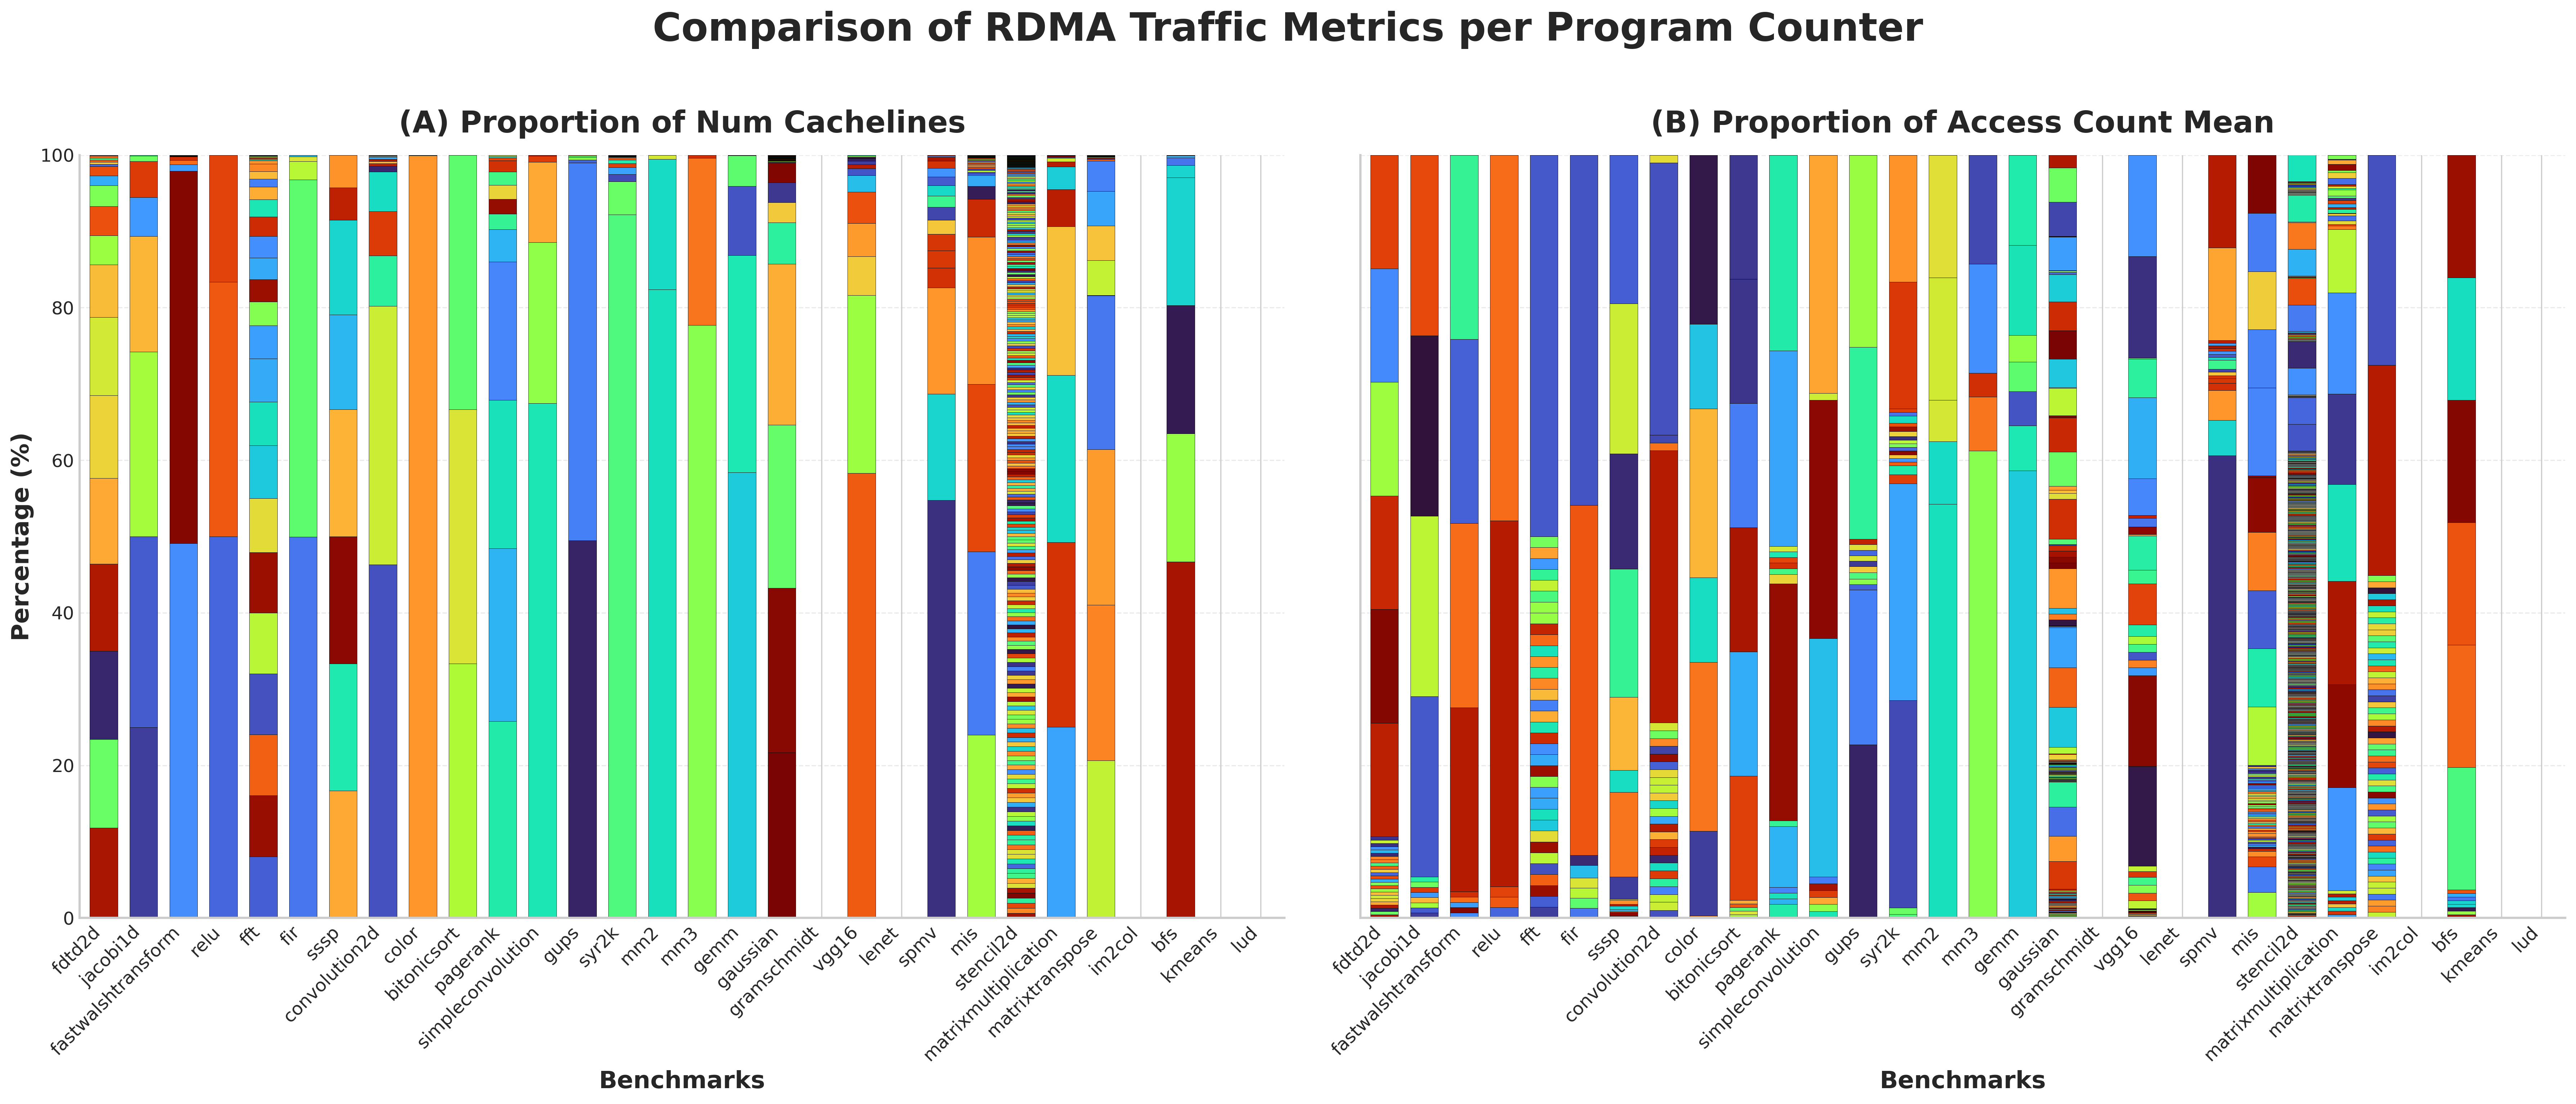

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import numpy as np
import random

# 1. 데이터 로드 및 통합
all_data = []
for benchmark in benchmarks:
    file_path = f"{rdma_metrics_dir}/{benchmark}_rdma_count_per_pc.csv"
    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        df['benchmark'] = benchmark
        all_data.append(df)
combined_df = pd.concat(all_data, ignore_index=True)
combined_df['pc'] = combined_df['pc'].astype(str)

# 2. 데이터 피벗 (왼쪽 축용: num_cachelines 비율)
pivot_df_lines = combined_df.pivot_table(index='benchmark', columns='pc', 
                                         values='num_cachelines', aggfunc='sum').fillna(0)
pivot_df_lines = pivot_df_lines.reindex(benchmarks)
pivot_perc_lines = pivot_df_lines.div(pivot_df_lines.sum(axis=1), axis=0) * 100

# 3. 데이터 피벗 (오른쪽 축용: access_count_mean 비중)
# 주의: 평균값의 평균을 내는 것보다, 벤치마크별 PC의 상대적 '강도'를 보기 위해 sum을 하거나 가중평균을 사용합니다.
# 여기서는 PC별 access_count_mean의 비중을 누적으로 보여줍니다.
pivot_df_mean = combined_df.pivot_table(index='benchmark', columns='pc', 
                                        values='access_count_mean', aggfunc='mean').fillna(0)
pivot_df_mean = pivot_df_mean.reindex(benchmarks)
# Mean 값들의 합을 100%로 환산하여 누적 비중으로 표시
pivot_perc_mean = pivot_df_mean.div(pivot_df_mean.sum(axis=1), axis=0) * 100

# [중요] PC 정렬 순서 및 색상 고정
sorted_pcs = combined_df.groupby('pc')['num_cachelines'].sum().sort_values(ascending=False).index
num_pcs = len(sorted_pcs)

# 고대비 셔플 컬러 생성 (두 차트 모두 이 리스트를 사용)
base_cmap = plt.get_cmap('turbo')
all_colors = [base_cmap(i) for i in np.linspace(0, 1, num_pcs)]
random.seed(42)
random.shuffle(all_colors)
pc_color_map = dict(zip(sorted_pcs, all_colors))

# 4. 시각화 (Subplots 1x2 구조)
plt.rcParams.update({'font.family': 'Arial', 'font.size': 12})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(24, 10), dpi=300, sharey=True)

# --- 왼쪽 그래프: Num Cachelines % ---
pivot_perc_lines[sorted_pcs].plot(kind='bar', stacked=True, ax=ax1, 
                                  color=[pc_color_map[pc] for pc in sorted_pcs],
                                  width=0.7, edgecolor='black', linewidth=0.2, legend=False)
ax1.set_title('(A) Proportion of Num Cachelines', fontsize=20, fontweight='bold', pad=15)
ax1.set_ylabel('Percentage (%)', fontsize=16, fontweight='bold')
ax1.set_ylim(0, 100)

# --- 오른쪽 그래프: Access Count Mean % ---
pivot_perc_mean[sorted_pcs].plot(kind='bar', stacked=True, ax=ax2, 
                                 color=[pc_color_map[pc] for pc in sorted_pcs],
                                 width=0.7, edgecolor='black', linewidth=0.2, legend=False)
ax2.set_title('(B) Proportion of Access Count Mean', fontsize=20, fontweight='bold', pad=15)
ax2.set_ylabel('Percentage (%)', fontsize=16, fontweight='bold') # sharey=True이므로 생략 가능하나 명시
ax2.set_ylim(0, 100)

# 공통 레이아웃 설정
for ax in [ax1, ax2]:
    ax.set_xlabel('Benchmarks', fontsize=16, fontweight='bold')
    ax.set_xticklabels(benchmarks, rotation=45, ha='right')
    ax.yaxis.grid(True, linestyle='--', alpha=0.4)
    sns.despine(ax=ax)

plt.suptitle('Comparison of RDMA Traffic Metrics per Program Counter', fontsize=26, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()